# **Parte 1 – Recolección de noticias** 

## Paso 1: Configuración inicial

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Dato | Valor |
|---|---|
| Fecha de descarga | 2026-10-18 |
| Opción | B – El Comercio |
| robots.txt | https://elcomercio.pe/robots.txt |
| Sitemaps | https://elcomercio.pe/sitemap/news/{seccion}/?outputType=xml |
| Secciones | politica, economia, tecnologia, deporte-total |
| Bajada | etiqueta `<meta name="description">` de cada noticia |

**Por qué El Comercio.** Revisé La República: su RSS trae solo 12–34 noticias por sección
y su robots.txt prohíbe la paginación (`Disallow: /*/pag/`). El Comercio publica en su
robots.txt un sitemap de noticias por sección con las 100 más recientes.
**Buenas prácticas:** User-Agent que identifica el proyecto, pausa de 1.5 s entre
solicitudes, máximo 1 reintento y ninguna ruta prohibida.


In [1]:
import time
from pathlib import Path
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser

import requests
from bs4 import BeautifulSoup
import pandas as pd
import plotly.express as px
import plotly.io as pio

# Interactivo en VS Code y, además, como imagen PNG para que se vea en GitHub
pio.renderers.default = "plotly_mimetype+png"

In [2]:
FECHA_DESCARGA = "2026-10-17"
MEDIO = "El Comercio"
SECCIONES = ["politica", "economia", "tecnologia", "deporte-total"]

ENCABEZADOS = {
    "User-Agent": "TareaPUCP-clasificador-noticias/1.0 (proyecto academico; github.com/NoeliaLRuiz)"
}
PAUSA_SEGUNDOS = 1.5

CARPETA_DATOS = Path("datos")
CARPETA_CRUDOS = CARPETA_DATOS / "raw"
CARPETA_CRUDOS.mkdir(parents=True, exist_ok=True)

### Revisión de robots.txt
Antes de descargar, reviso qué permite El Comercio. Su robots.txt permite leer los sitemaps de noticias y prohíbe, por ejemplo, el buscador (`/buscar/`). La celda lo comprueba: debe responder `True` para el sitemap y `False` para el buscador.

In [3]:
respuesta = requests.get("https://elcomercio.pe/robots.txt", headers=ENCABEZADOS, timeout=20)
robots = RobotFileParser()
robots.parse(respuesta.text.splitlines())

agente = ENCABEZADOS["User-Agent"]
url_sitemap = "https://elcomercio.pe/sitemap/news/politica/?outputType=xml"
url_buscador = "https://elcomercio.pe/buscar/congreso/"
print("¿Puedo leer el sitemap?", robots.can_fetch(agente, url_sitemap))
print("¿Puedo usar el buscador?", robots.can_fetch(agente, url_buscador))

¿Puedo leer el sitemap? True
¿Puedo usar el buscador? False


## Paso 2: Extracción

### Descarga de noticias
Todas las solicitudes pasan por una sola función, `descargar()`, para que cumplan las mismas reglas: se identifican con un User-Agent propio, esperan 1.5 segundos después de cada
solicitud y reintentan una sola vez si algo falla.


In [4]:
def descargar(url):
    """Descarga una página con pausa y como máximo 1 reintento."""
    for intento in [1, 2]:
        try:
            respuesta = requests.get(url, headers=ENCABEZADOS, timeout=20)
            time.sleep(PAUSA_SEGUNDOS)
            if respuesta.status_code == 200:
                return respuesta.text
            print("Código", respuesta.status_code, "en", url)
        except requests.RequestException as error:
            print("Error en el intento", intento, ":", error)
            time.sleep(PAUSA_SEGUNDOS)
    return None

### Sitemaps de noticias
El Comercio publica un sitemap de noticias por sección con las 100 más recientes (titular, URL y fecha). Descargo los de política, economía, tecnología y deporte, y guardo cada XML en `datos/raw/` como respaldo crudo. Si el archivo ya existe, no se vuelve a descargar: así, al ejecutar de nuevo el notebook, los datos no cambian.

In [5]:
for seccion in SECCIONES:
    archivo = CARPETA_CRUDOS / f"sitemap_{seccion}_{FECHA_DESCARGA}.xml"
    if archivo.exists():
        print("Ya estaba descargado:", archivo.name)
        continue
    texto = descargar(f"https://elcomercio.pe/sitemap/news/{seccion}/?outputType=xml")
    if texto is not None:
        archivo.write_text(texto, encoding="utf-8")
        print("Guardado:", archivo.name)

Ya estaba descargado: sitemap_politica_2026-10-17.xml
Ya estaba descargado: sitemap_economia_2026-10-17.xml
Ya estaba descargado: sitemap_tecnologia_2026-10-17.xml
Ya estaba descargado: sitemap_deporte-total_2026-10-17.xml


In [6]:
filas = []
for archivo in sorted(CARPETA_CRUDOS.glob("sitemap_*.xml")):
    sopa = BeautifulSoup(archivo.read_text(encoding="utf-8"), "xml")
    for noticia in sopa.find_all("url"):
        titular = noticia.find("news:title")
        fecha = noticia.find("news:publication_date")
        filas.append({
            "url": noticia.find("loc").get_text(strip=True),
            "titular": titular.get_text(strip=True) if titular else "",
            "fecha": fecha.get_text(strip=True)[:10] if fecha else "",
        })

noticias_crudas = pd.DataFrame(filas)
print(noticias_crudas.shape)
noticias_crudas.head()

(400, 3)


,url,titular,fecha
0,https://elcomercio.pe/deporte-total/futbol-per...,El furioso “Que se dedique a administrar” de G...,2026-10-18
1,https://elcomercio.pe/deporte-total/futbol-per...,“El jugador peruano tiene un déficit grande en...,2026-10-18
2,https://elcomercio.pe/deporte-total/futbol-per...,“¿A quién le sirve un VAR que funciona con tan...,2026-10-18
3,https://elcomercio.pe/deporte-total/futbol-per...,Alianza Lima vs. Atlético Grau en vivo: minuto...,2026-10-17
4,https://elcomercio.pe/deporte-total/futbol-per...,¡Golazo! Vélez desparramó rivales y anotó el 3...,2026-10-17


Resultado: 400 noticias (100 por sitemap), publicadas entre el 6 y el 18 de octubre de 2026. Una misma URL aparece en dos sitemaps; se elimina en la limpieza.

### Bajadas
El sitemap no trae la bajada. La tomo de la etiqueta `<meta name="description">` de cada noticia, visitándolas una por una (399 páginas, unos 15 minutos). El avance se guarda cada
25 noticias en `datos/raw/bajadas.csv`, para retomar si la descarga se corta. No guardo el HTML completo de cada página porque pesaría unos 200 MB.

In [7]:
archivo_bajadas = CARPETA_CRUDOS / "bajadas.csv"
if archivo_bajadas.exists():
    bajadas = pd.read_csv(archivo_bajadas)
else:
    bajadas = pd.DataFrame(columns=["url", "bajada"])

urls_ya_visitadas = set(bajadas["url"])
urls_pendientes = []
for url in noticias_crudas["url"].drop_duplicates():
    if url not in urls_ya_visitadas:
        urls_pendientes.append(url)
print("Noticias por visitar:", len(urls_pendientes))

Noticias por visitar: 0


In [8]:
nuevas = []
for numero, url in enumerate(urls_pendientes, start=1):
    html = descargar(url)
    bajada = ""
    if html is not None:
        sopa = BeautifulSoup(html, "lxml")
        meta = sopa.find("meta", attrs={"name": "description"})
        if meta is not None:
            bajada = meta.get("content", "").strip()
    nuevas.append({"url": url, "bajada": bajada})

    if numero % 25 == 0 or numero == len(urls_pendientes):
        bajadas = pd.concat([bajadas, pd.DataFrame(nuevas)], ignore_index=True)
        bajadas.to_csv(archivo_bajadas, index=False, encoding="utf-8")
        nuevas = []
        print("Avance:", numero, "de", len(urls_pendientes))

In [9]:
print("Bajadas guardadas en total:", len(bajadas))

Bajadas guardadas en total: 399


Resultado: 399 bajadas, una por cada URL distinta, ninguna vacía.

### Tabla de trabajo
Uno titulares y bajadas por URL, agrego el nombre del medio y saco la sección original de la ruta de la URL (por ejemplo, `politica/congreso`). Con esa sección se hace el mapeo a las 4 categorías en la limpieza.

In [10]:
bajadas = bajadas.drop_duplicates(subset="url")
noticias = noticias_crudas.merge(bajadas, on="url", how="left")
noticias["bajada"] = noticias["bajada"].fillna("")
noticias["medio"] = MEDIO

def seccion_desde_url(url):
    """'https://elcomercio.pe/politica/congreso/titulo-noticia/' -> 'politica/congreso'"""
    partes = urlparse(url).path.strip("/").split("/")
    return "/".join(partes[:-1])

noticias["seccion_original"] = noticias["url"].apply(seccion_desde_url)
noticias["seccion_original"].value_counts()

seccion_original
economia/peru                         46
tecnologia/actualidad                 37
deporte-total/futbol-peruano          31
politica/congreso                     27
politica                              24
politica/gobierno                     20
tecnologia/inteligencia-artificial    19
deporte-total/futbol-mundial          19
economia/mercados                     18
deporte-total                         16
economia                              14
tecnologia/ciencias                   11
economia/dia-1                        10
economia/opinion                       9
politica/actualidad                    8
deporte-total/argentina                8
deporte-total/polideportivo            8
tecnologia/ciberseguridad              7
tecnologia/ecologia                    6
tecnologia/videojuegos                 5
politica/internacional                 5
tecnologia/moviles                     4
deporte-total/espana                   4
ecdata                                 4

## Paso 3: Limpieza y normalización
Elimino las noticias con URL repetida, con titular vacío o con el mismo titular en dos URL (si una quedara en train y la otra en test, el modelo "vería" el test). Cada descarte se anota con su motivo para reportarlo al final.

In [11]:
registro_descartes = []

antes = len(noticias)
noticias = noticias.drop_duplicates(subset="url")
registro_descartes.append({"motivo": "URL duplicada", "noticias": antes - len(noticias)})

antes = len(noticias)
noticias = noticias[noticias["titular"].str.strip() != ""]
registro_descartes.append({"motivo": "Titular vacío", "noticias": antes - len(noticias)})

# Un mismo titular en dos URL podría quedar una vez en train y otra en test
antes = len(noticias)
noticias = noticias.drop_duplicates(subset="titular")
registro_descartes.append({"motivo": "Mismo titular con otra URL", "noticias": antes - len(noticias)})

### Mapeo de secciones a las 4 categorías
La sección original sale de la URL (por ejemplo, `politica/congreso`). Tomo su primera parte y la traduzco a una de las 4 categorías: `politica`, `economia`, `deporte-total` → `deportes` y `tecnologia` → `ciencia_tecnologia`. La tabla muestra a qué categoría va cada sección.

In [12]:
MAPEO_SECCION = {
    "politica": "politica",
    "economia": "economia",
    "deporte-total": "deportes",
    "tecnologia": "ciencia_tecnologia",
}
noticias["seccion_principal"] = noticias["seccion_original"].str.split("/").str[0]
noticias["etiqueta"] = noticias["seccion_principal"].map(MAPEO_SECCION)

tabla_equivalencias = noticias.groupby("seccion_original", as_index=False).agg(
    etiqueta=("etiqueta", "first"),
    noticias=("url", "count"),
)
tabla_equivalencias["etiqueta"] = tabla_equivalencias["etiqueta"].fillna("descartada")
tabla_equivalencias.sort_values(["etiqueta", "noticias"], ascending=[True, False])

,seccion_original,etiqueta,noticias
32,tecnologia/actualidad,ciencia_tecnologia,37
37,tecnologia/inteligencia-artificial,ciencia_tecnologia,19
34,tecnologia/ciencias,ciencia_tecnologia,10
33,tecnologia/ciberseguridad,ciencia_tecnologia,7
35,tecnologia/ecologia,ciencia_tecnologia,6
42,tecnologia/videojuegos,ciencia_tecnologia,5
38,tecnologia/moviles,ciencia_tecnologia,4
36,tecnologia/gadgets,ciencia_tecnologia,3
39,tecnologia/redes-sociales,ciencia_tecnologia,2
40,tecnologia/robotica,ciencia_tecnologia,1


### Noticias fuera de las 4 categorías
Las secciones que no corresponden a ninguna categoría (opinión, gráficos de datos, autos, etc.) se descartan. No se crea una quinta categoría.

In [13]:
fuera_de_categoria = noticias[noticias["etiqueta"].isna()]
motivo = "Sección fuera de las 4 categorías"
registro_descartes.append({"motivo": motivo, "noticias": len(fuera_de_categoria)})
noticias = noticias[noticias["etiqueta"].notna()].copy()

print("Secciones descartadas:")
print(fuera_de_categoria["seccion_original"].value_counts())

Secciones descartadas:
seccion_original
ecdata                       4
opinion/columnistas          4
elecciones                   2
ruedas-tuercas/automotriz    2
bbc-news-mundo               2
eldominical/ciencia          1
Name: count, dtype: int64


In [14]:
reporte_descartes = pd.DataFrame(registro_descartes)
print("Descargadas:", len(noticias_crudas))
print("Descartadas:", reporte_descartes["noticias"].sum())
print("Finales:", len(noticias))
print("Sin bajada (se conservan):", (noticias["bajada"] == "").sum())
reporte_descartes

Descargadas: 400
Descartadas: 16
Finales: 384
Sin bajada (se conservan): 0


,motivo,noticias
0,URL duplicada,1
1,Titular vacío,0
2,Mismo titular con otra URL,0
3,Sección fuera de las 4 categorías,15


**Resultado:** de 400 noticias descargadas se descartaron 16: 1 URL repetida y 15 de secciones fuera de las 4 categorías (ecdata 4, columnas de opinión 4, elecciones 2, autos 2, BBC Mundo 2 y El Dominical 1). No hubo titulares vacíos ni repetidos.
Quedan **384 noticias**, todas con bajada.

## Paso 4: Análisis exploratorio
Tres gráficos con Plotly. El título de cada uno dice la conclusión, no solo la variable.

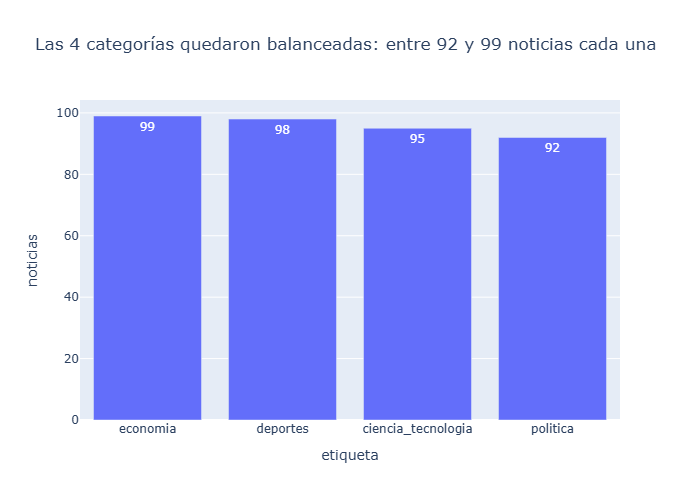

In [15]:
conteo_categorias = noticias["etiqueta"].value_counts().reset_index()
conteo_categorias.columns = ["etiqueta", "noticias"]
minimo = conteo_categorias["noticias"].min()
maximo = conteo_categorias["noticias"].max()

figura_categorias = px.bar(
    conteo_categorias, x="etiqueta", y="noticias", text="noticias",
    title=f"Las 4 categorías quedaron balanceadas: entre {minimo} y {maximo} noticias cada una",
)
figura_categorias.show()

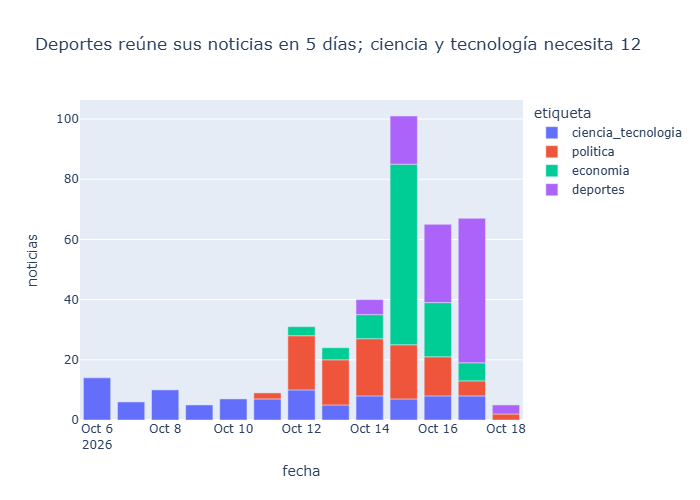

In [16]:
noticias_por_dia = noticias.groupby(["fecha", "etiqueta"]).size().reset_index(name="noticias")
titulo_fechas = "Deportes reúne sus noticias en 5 días; ciencia y tecnología necesita 12"
figura_fechas = px.bar(
    noticias_por_dia, x="fecha", y="noticias", color="etiqueta", title=titulo_fechas,
)
figura_fechas.show()

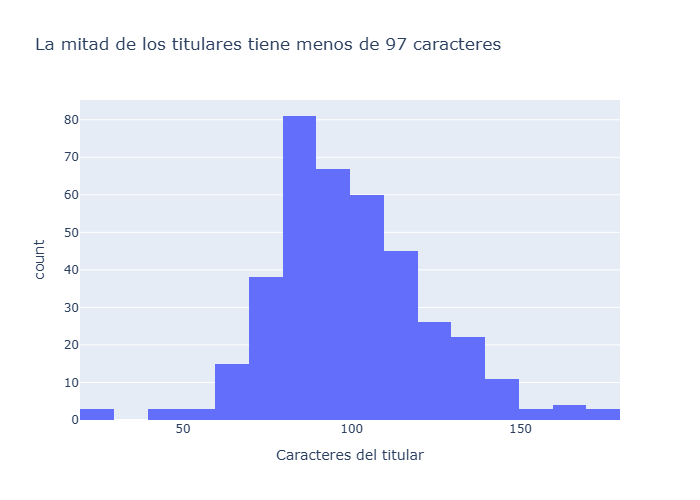

In [17]:
noticias["largo_titular"] = noticias["titular"].str.len()
mediana_largo = int(noticias["largo_titular"].median())
titulo_largo = f"La mitad de los titulares tiene menos de {mediana_largo} caracteres"

figura_largo = px.histogram(
    noticias, x="largo_titular", nbins=30, title=titulo_largo,
    labels={"largo_titular": "Caracteres del titular"},
)
figura_largo.show()

### Validación con los extremos
Reviso los 5 titulares más largos y los 5 más cortos para comprobar que coinciden con las colas del histograma.

In [18]:
columnas_ver = ["titular", "largo_titular", "etiqueta"]
print("5 titulares más largos")
display(noticias.nlargest(5, "largo_titular")[columnas_ver])
print("5 titulares más cortos")
display(noticias.nsmallest(5, "largo_titular")[columnas_ver])

5 titulares más largos


,titular,largo_titular,etiqueta
1,“El jugador peruano tiene un déficit grande en...,178,deportes
0,El furioso “Que se dedique a administrar” de G...,171,deportes
78,“Con Mano Menezes el mejor jugador de la selec...,171,deportes
48,“Creo que puedo llegar a un top 3 sin que nadi...,167,deportes
255,Keiko Fujimori sobre Álvaro Vargas Llosa: “Con...,166,politica


5 titulares más cortos


,titular,largo_titular,etiqueta
160,Invocación por el Perú,22,economia
102,AlaCena no tiene precio,23,economia
122,IA y Sandbox regulatorio,24,economia
174,La evolución de la confianza en los pagos,41,economia
104,Premio Nobel de Economía: la macro es micro,43,economia


**Resultado:** los más largos (166 a 178 caracteres) son casi todos de deportes y coinciden con la cola derecha del histograma. Los 5 más cortos (22 a 43 caracteres) son columnas de opinión de economía, como «Invocación por el Perú» o «AlaCena no tiene precio»: no describen
el tema de la noticia, así que serán difíciles de clasificar solo con el titular.

## Paso 5: Validación de URL y exportación
Compruebo que 5 URL al azar respondan y guardo `datos/noticias.csv` con las 7 columnas pedidas.

In [19]:
for url in noticias["url"].sample(5, random_state=42):
    respuesta = requests.get(url, headers=ENCABEZADOS, timeout=20)
    print(respuesta.status_code, url[:90])
    time.sleep(PAUSA_SEGUNDOS)

200 https://elcomercio.pe/politica/congreso/carlos-mesia-presidente-de-la-comision-de-constitu
200 https://elcomercio.pe/politica/elecciones/lima-puede-elegir-a-su-alcalde-en-segunda-vuelta
200 https://elcomercio.pe/tecnologia/actualidad/nasa-los-cuatro-astronautas-de-crew-12-retorna
200 https://elcomercio.pe/tecnologia/inteligencia-artificial/cientificos-descubren-como-predec
200 https://elcomercio.pe/deporte-total/caminos-del-inca-2026-el-dia-de-manana-me-encantaria-v


In [20]:
COLUMNAS_FINALES = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
noticias_final = noticias[COLUMNAS_FINALES]
noticias_final.to_csv(CARPETA_DATOS / "noticias.csv", index=False, encoding="utf-8")

print(noticias_final.shape)
noticias_final.head()

(384, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,El furioso “Que se dedique a administrar” de G...,"Con goles de Kevin Quevedo, Eryc Castillo y Ja...",El Comercio,deporte-total/futbol-peruano,https://elcomercio.pe/deporte-total/futbol-per...,2026-10-18,deportes
1,“El jugador peruano tiene un déficit grande en...,“El jugador peruano tiene un déficit grande en...,El Comercio,deporte-total/futbol-peruano,https://elcomercio.pe/deporte-total/futbol-per...,2026-10-18,deportes
2,“¿A quién le sirve un VAR que funciona con tan...,“¿A quién le sirve un VAR que funciona con tan...,El Comercio,deporte-total/futbol-peruano,https://elcomercio.pe/deporte-total/futbol-per...,2026-10-18,deportes
3,Alianza Lima vs. Atlético Grau en vivo: minuto...,Sigue la transmisión de Alianza Lima vs. Atlét...,El Comercio,deporte-total/futbol-peruano,https://elcomercio.pe/deporte-total/futbol-per...,2026-10-17,deportes
4,¡Golazo! Vélez desparramó rivales y anotó el 3...,El volante blanquiazul se lució a los 83 minut...,El Comercio,deporte-total/futbol-peruano,https://elcomercio.pe/deporte-total/futbol-per...,2026-10-17,deportes


**Resultado:** `datos/noticias.csv` con 384 noticias y 7 columnas (titular, bajada, medio,seccion_original, url, fecha, etiqueta): economía 99, deportes 98, ciencia y tecnología 95 y política 92.